SCHEDULE DELAY PREDICTION

Dataset shape: (190, 26)

Columns:
['Project_ID', 'Location', 'Planned_Cost', 'Planned_Duration', 'Start_Year', 'Start_Month', 'Start_Quarter', 'Weather_Condition', 'Temperature', 'Humidity', 'Air_Quality_Index', 'Energy_Consumption', 'Material_Usage', 'Labor_Hours', 'Equipment_Utilization', 'Accident_Count', 'Safety_Risk_Score', 'Vibration_Level', 'Crack_Width', 'Load_Bearing_Capacity', 'Actual_Duration', 'Actual_Cost', 'Delay_Percentage', 'Cost_Overrun_Percentage', 'Schedule_Delay', 'Cost_Overrun']

Target distribution:
Schedule_Delay
Yes    134
No      56
Name: count, dtype: int64

Data leakage check: PASSED

Numerical features:
['Planned_Cost', 'Planned_Duration', 'Start_Year', 'Start_Month', 'Start_Quarter', 'Temperature', 'Humidity', 'Air_Quality_Index', 'Material_Usage', 'Labor_Hours', 'Equipment_Utilization', 'Energy_Consumption', 'Accident_Count', 'Safety_Risk_Score', 'Vibration_Level', 'Crack_Width', 'Load_Bearing_Capacity']

Categorical features:
[

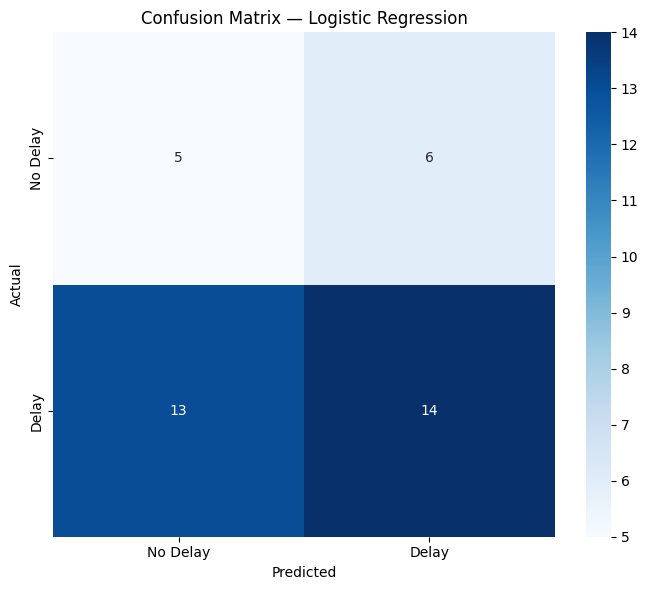

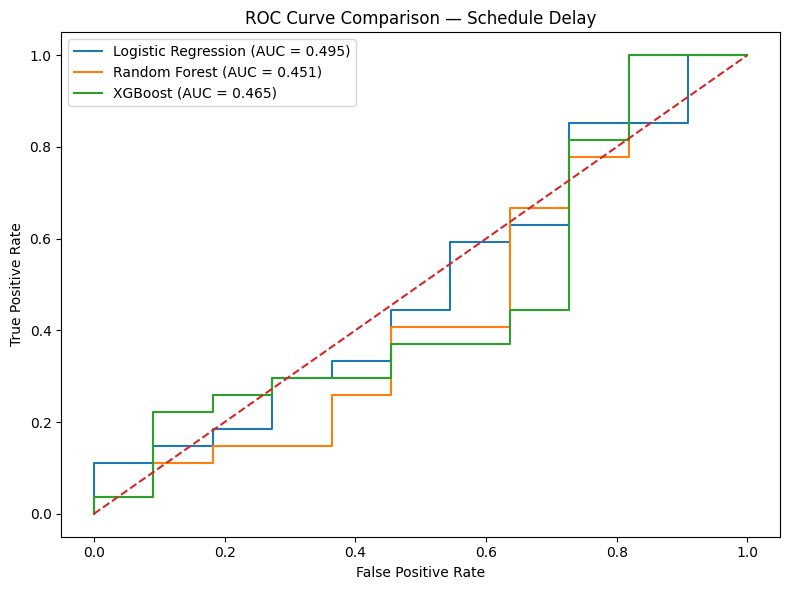



CODE 1 COMPLETED

Best model for Schedule Delay:
Logistic Regression

ROC-AUC: 0.4949

Saved files:
models/best_delay_model.pkl
models/delay_preprocessor.pkl
models/delay_features.pkl
results/delay_model_comparison.csv
results/best_delay_model_evaluation.csv
results/delay_test_predictions.csv
results/delay_confusion_matrix.png
results/delay_roc_curve_comparison.png

These model files will be used by:
CODE 3 → Probability Prediction
CODE 4 → SHAP Explanation


In [2]:
# SCHEDULE DELAY PREDICTION


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import warnings
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


# ============================================================
# 2. Input Data
# ============================================================

INPUT_FILE = "building_final_processed_data.csv"

MODEL_FOLDER = "models"

RESULT_FOLDER = "results"

os.makedirs(
    MODEL_FOLDER,
    exist_ok=True
)

os.makedirs(
    RESULT_FOLDER,
    exist_ok=True
)

RANDOM_STATE = 42

TEST_SIZE = 0.20


# ============================================================
# 3. LOAD DATA
# ============================================================

df = pd.read_csv(
    INPUT_FILE
)


print("=" * 70)
print("SCHEDULE DELAY PREDICTION")
print("=" * 70)

print(
    "\nDataset shape:",
    df.shape
)

print(
    "\nColumns:"
)

print(
    df.columns.tolist()
)


# ============================================================
# 4. TARGET VARIABLE
# ============================================================

TARGET = "Schedule_Delay"


if TARGET not in df.columns:

    raise ValueError(
        f"Target column '{TARGET}' "
        "was not found in the dataset."
    )


print(
    "\nTarget distribution:"
)

print(
    df[TARGET].value_counts()
)


# ============================================================
# 5. CONVERT TARGET TO 0/1
# ============================================================

# Yes = 1
# No  = 0

y = (

    df[TARGET]
    .map({
        "No": 0,
        "Yes": 1
    })

)


if y.isnull().any():

    raise ValueError(
        "Schedule_Delay contains values "
        "other than 'Yes' and 'No'."
    )


y = y.astype(int)


# ============================================================
# 6. SELECT PROJECT-RELEVANT FEATURES
# ============================================================

# These are variables that can reasonably be used to
# predict schedule delay.
#
# IMPORTANT:
# Actual/final outcome variables are NOT included.

selected_features = [

    # Project planning
    "Planned_Cost",
    "Planned_Duration",

    # Project start timing
    "Start_Year",
    "Start_Month",
    "Start_Quarter",

    # Location
    "Location",

    # Weather/environment
    "Weather_Condition",
    "Temperature",
    "Humidity",
    "Air_Quality_Index",

    # Resources/construction
    "Material_Usage",
    "Labor_Hours",
    "Equipment_Utilization",
    "Energy_Consumption",

    # Safety
    "Accident_Count",
    "Safety_Risk_Score",

    # Building/site condition
    "Vibration_Level",
    "Crack_Width",
    "Load_Bearing_Capacity"

]


# Check that every feature exists

missing_features = [

    feature
    for feature in selected_features
    if feature not in df.columns

]


if missing_features:

    raise ValueError(
        "The following selected features "
        "are missing from the dataset:\n"
        +
        "\n".join(missing_features)
    )


X = df[
    selected_features
].copy()


# ============================================================
# 7. EXPLICIT LEAKAGE CHECK
# ============================================================

# These variables must NEVER enter the schedule-delay model.

forbidden_features = [

    "Actual_Duration",
    "Actual_Cost",

    "Delay_Percentage",
    "Cost_Overrun_Percentage",

    "Schedule_Delay",
    "Cost_Overrun",

    "Project_ID"

]


leakage_present = [

    feature
    for feature in forbidden_features
    if feature in X.columns

]


if leakage_present:

    raise ValueError(
        "DATA LEAKAGE DETECTED!\n"
        "The following forbidden variables "
        "are present in X:\n"
        +
        "\n".join(leakage_present)
    )


print(
    "\nData leakage check: PASSED"
)


# ============================================================
# 8. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numerical_features = (

    X
    .select_dtypes(
        include=np.number
    )
    .columns
    .tolist()

)


categorical_features = (

    X
    .select_dtypes(
        exclude=np.number
    )
    .columns
    .tolist()

)


print(
    "\nNumerical features:"
)

print(
    numerical_features
)


print(
    "\nCategorical features:"
)

print(
    categorical_features
)


# ============================================================
# 9. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = (

    train_test_split(

        X,
        y,

        test_size=TEST_SIZE,

        random_state=RANDOM_STATE,

        stratify=y

    )

)


print(
    "\nTraining samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)


# ============================================================
# 10. NUMERICAL PREPROCESSING
# ============================================================

numerical_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )

        ),

        (
            "scaler",

            StandardScaler()

        )

    ]

)


# ============================================================
# 11. CATEGORICAL PREPROCESSING
# ============================================================

try:

    one_hot_encoder = OneHotEncoder(

        handle_unknown="ignore",

        sparse_output=False

    )

except TypeError:

    # Compatibility with older scikit-learn

    one_hot_encoder = OneHotEncoder(

        handle_unknown="ignore",

        sparse=False

    )


categorical_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="most_frequent"
            )

        ),

        (
            "onehot",

            one_hot_encoder

        )

    ]

)


# ============================================================
# 12. COMBINE PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",

            numerical_pipeline,

            numerical_features

        ),

        (
            "categorical",

            categorical_pipeline,

            categorical_features

        )

    ],

    remainder="drop",

    verbose_feature_names_out=False

)


# ============================================================
# 13. DEFINE MODELS
# ============================================================

models = {

    "Logistic Regression":

        LogisticRegression(

            max_iter=2000,

            class_weight="balanced",

            random_state=RANDOM_STATE

        ),


    "Random Forest":

        RandomForestClassifier(

            n_estimators=300,

            max_depth=None,

            min_samples_split=5,

            min_samples_leaf=2,

            class_weight="balanced",

            random_state=RANDOM_STATE,

            n_jobs=-1

        ),


    "XGBoost":

        XGBClassifier(

            n_estimators=300,

            max_depth=4,

            learning_rate=0.05,

            subsample=0.8,

            colsample_bytree=0.8,

            eval_metric="logloss",

            random_state=RANDOM_STATE,

            n_jobs=-1

        )

}


# ============================================================
# 14. TRAIN AND EVALUATE MODELS
# ============================================================

results = []

trained_models = {}


for model_name, model in models.items():

    print("\n")
    print("=" * 70)

    print(
        f"TRAINING: {model_name}"
    )

    print(
        "=" * 70
    )


    # --------------------------------------------
    # Create complete pipeline
    # --------------------------------------------

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",

                preprocessor

            ),

            (
                "model",

                model

            )

        ]

    )


    # --------------------------------------------
    # Train
    # --------------------------------------------

    pipeline.fit(
        X_train,
        y_train
    )


    # --------------------------------------------
    # Predictions
    # --------------------------------------------

    y_pred = pipeline.predict(
        X_test
    )


    y_probability = (

        pipeline
        .predict_proba(X_test)[:, 1]

    )


    # --------------------------------------------
    # Metrics
    # --------------------------------------------

    accuracy = accuracy_score(

        y_test,
        y_pred

    )


    precision = precision_score(

        y_test,
        y_pred,
        zero_division=0

    )


    recall = recall_score(

        y_test,
        y_pred,
        zero_division=0

    )


    f1 = f1_score(

        y_test,
        y_pred,
        zero_division=0

    )


    roc_auc = roc_auc_score(

        y_test,
        y_probability

    )


    # --------------------------------------------
    # Store results
    # --------------------------------------------

    results.append({

        "Model":
            model_name,

        "Accuracy":
            accuracy,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1_Score":
            f1,

        "ROC_AUC":
            roc_auc

    })


    trained_models[
        model_name
    ] = pipeline


    # --------------------------------------------
    # Print results
    # --------------------------------------------

    print(
        "\nAccuracy:",
        round(accuracy, 4)
    )

    print(
        "Precision:",
        round(precision, 4)
    )

    print(
        "Recall:",
        round(recall, 4)
    )

    print(
        "F1 Score:",
        round(f1, 4)
    )

    print(
        "ROC-AUC:",
        round(roc_auc, 4)
    )

    print(
        "\nClassification Report:"
    )

    print(

        classification_report(

            y_test,

            y_pred,

            target_names=[
                "No Delay",
                "Delay"
            ],

            zero_division=0

        )

    )


# ============================================================
# 15. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    results
)


results_df = (

    results_df
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .reset_index(
        drop=True
    )

)


print("\n")
print("=" * 70)
print("MODEL COMPARISON — SCHEDULE DELAY")
print("=" * 70)

print(
    results_df
)


# Save comparison

results_df.to_csv(

    os.path.join(

        RESULT_FOLDER,

        "delay_model_comparison.csv"

    ),

    index=False

)


# ============================================================
# 16. SELECT BEST MODEL
# ============================================================

# ROC-AUC is used as the primary comparison metric.
# F1 score is also reported because this is a classification
# problem where identifying delayed projects is important.

best_model_name = (

    results_df
    .iloc[0]["Model"]

)


best_model = (

    trained_models[
        best_model_name
    ]

)


print(
    "\nBEST SCHEDULE DELAY MODEL:"
)

print(
    best_model_name
)


# ============================================================
# 17. SAVE BEST MODEL
# ============================================================

joblib.dump(

    best_model,

    os.path.join(

        MODEL_FOLDER,

        "best_delay_model.pkl"

    )

)


# ============================================================
# 18. SAVE FEATURE LIST
# ============================================================

joblib.dump(

    selected_features,

    os.path.join(

        MODEL_FOLDER,

        "delay_features.pkl"

    )

)


# ============================================================
# 19. SAVE PREPROCESSOR
# ============================================================

# Extract preprocessing object from the trained pipeline.

best_preprocessor = (

    best_model
    .named_steps[
        "preprocessor"
    ]

)


joblib.dump(

    best_preprocessor,

    os.path.join(

        MODEL_FOLDER,

        "delay_preprocessor.pkl"

    )

)


# ============================================================
# 20. BEST MODEL PREDICTIONS
# ============================================================

best_predictions = (

    best_model
    .predict(X_test)

)


best_probabilities = (

    best_model
    .predict_proba(X_test)[:, 1]

)


# ============================================================
# 21. SAVE TEST PREDICTIONS
# ============================================================

prediction_results = pd.DataFrame({

    "Actual":

        y_test.values,

    "Predicted":

        best_predictions,

    "Probability_of_Delay":

        best_probabilities

})


prediction_results[
    "Actual_Label"
] = prediction_results[
    "Actual"
].map({

    0: "No Delay",

    1: "Delay"

})


prediction_results[
    "Predicted_Label"
] = prediction_results[
    "Predicted"
].map({

    0: "No Delay",

    1: "Delay"

})


prediction_results.to_csv(

    os.path.join(

        RESULT_FOLDER,

        "delay_test_predictions.csv"

    ),

    index=False

)


# ============================================================
# 22. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_test,

    best_predictions

)


plt.figure(

    figsize=(7, 6)

)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=[
        "No Delay",
        "Delay"
    ],

    yticklabels=[
        "No Delay",
        "Delay"
    ]

)


plt.title(

    f"Confusion Matrix — {best_model_name}"

)


plt.xlabel(
    "Predicted"
)


plt.ylabel(
    "Actual"
)


plt.tight_layout()


plt.savefig(

    os.path.join(

        RESULT_FOLDER,

        "delay_confusion_matrix.png"

    ),

    dpi=300

)


plt.show()


# ============================================================
# 23. ROC CURVES FOR ALL MODELS
# ============================================================

plt.figure(

    figsize=(8, 6)

)


for model_name, pipeline in trained_models.items():

    probability = (

        pipeline
        .predict_proba(X_test)[:, 1]

    )


    fpr, tpr, _ = roc_curve(

        y_test,

        probability

    )


    auc_score = roc_auc_score(

        y_test,

        probability

    )


    plt.plot(

        fpr,

        tpr,

        label=f"{model_name} (AUC = {auc_score:.3f})"

    )


plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"

)


plt.title(
    "ROC Curve Comparison — Schedule Delay"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(

        RESULT_FOLDER,

        "delay_roc_curve_comparison.png"

    ),

    dpi=300

)

plt.show()


# ============================================================
# 24. SAVE BEST MODEL EVALUATION
# ============================================================

best_row = (

    results_df[
        results_df["Model"]
        ==
        best_model_name
    ]

    .iloc[0]

)


best_evaluation = pd.DataFrame({

    "Metric": [

        "Best Model",

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "ROC-AUC"

    ],

    "Value": [

        best_model_name,

        best_row["Accuracy"],

        best_row["Precision"],

        best_row["Recall"],

        best_row["F1_Score"],

        best_row["ROC_AUC"]

    ]

})


best_evaluation.to_csv(

    os.path.join(

        RESULT_FOLDER,

        "best_delay_model_evaluation.csv"

    ),

    index=False

)


# ============================================================
# 25. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("CODE 1 COMPLETED")
print("=" * 70)


print(
    "\nBest model for Schedule Delay:"
)

print(
    best_model_name
)


print(
    "\nROC-AUC:",
    round(
        best_row["ROC_AUC"],
        4
    )
)


print(
    "\nSaved files:"
)


print(
    "models/best_delay_model.pkl"
)


print(
    "models/delay_preprocessor.pkl"
)


print(
    "models/delay_features.pkl"
)


print(
    "results/delay_model_comparison.csv"
)


print(
    "results/best_delay_model_evaluation.csv"
)


print(
    "results/delay_test_predictions.csv"
)


print(
    "results/delay_confusion_matrix.png"
)


print(
    "results/delay_roc_curve_comparison.png"
)


print(
    "\nThese model files will be used by:"
)


print(
    "CODE 3 → Probability Prediction"
)


print(
    "CODE 4 → SHAP Explanation"
)